# Experimento: CNN sobre CIFAR-10 (semilla 82)
**Evaluación Segunda Unidad – IA – UAC** · Gonzalo Fredy Puelles Zapata · Código 022101082H

Este notebook contiene las pruebas, el EDA y la visualización de muestras.
Ejecuta **Kernel → Restart & Run All** antes de hacer `commit` para que las salidas queden guardadas.

## 1. Configuración y semilla

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))   # permite importar los módulos de src/

import numpy as np
import torch
import matplotlib.pyplot as plt

from dataset import (SEED, CLASSES, set_seed, get_dataloaders, show_samples,
                     show_augmentation, denormalize, DATA_DIR)
from model import CNN, count_parameters

set_seed(SEED)
print("Semilla individual:", SEED)
print("PyTorch:", torch.__version__, "| GPU disponible:", torch.cuda.is_available())

Semilla individual: 82
PyTorch: 2.15.0+cpu | GPU disponible: False


## 2. Carga del dataset y partición estratificada (Pregunta 1)

In [2]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=128)

[Semilla] 82
[Particion] Entrenamiento : 40000 imagenes -> tensor (N, 3, 32, 32)
[Particion] Validacion    : 10000 imagenes -> tensor (N, 3, 32, 32)
[Particion] Prueba (test) : 10000 imagenes -> tensor (N, 3, 32, 32)
[Estratificacion] imagenes por clase en train: [4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000]
[Estratificacion] imagenes por clase en val  : [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
[Batch] x: (128, 3, 32, 32) (Batch, Channels, Height, Width) | y: (128,)


## 3. EDA: balance de clases y estadísticas de píxeles

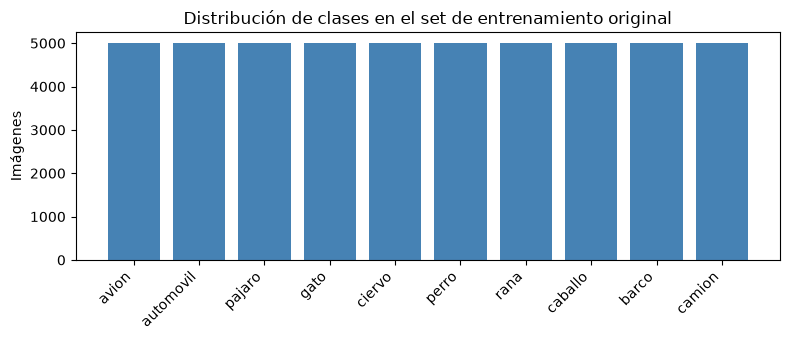

Shape del arreglo de imágenes : (50000, 32, 32, 3) (N, H, W, C)
Media por canal RGB : [0.4914 0.4822 0.4465]
Desv. estándar RGB  : [0.247  0.2435 0.2616]


In [3]:
from torchvision import datasets
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
targets = np.array(raw_train.targets)

counts = np.bincount(targets, minlength=10)
plt.figure(figsize=(8, 3.5))
plt.bar(CLASSES, counts, color="steelblue")
plt.xticks(rotation=45, ha="right"); plt.ylabel("Imágenes")
plt.title("Distribución de clases en el set de entrenamiento original")
plt.tight_layout(); plt.show()

data = raw_train.data / 255.0   # (50000, 32, 32, 3)
print("Shape del arreglo de imágenes :", raw_train.data.shape, "(N, H, W, C)")
print("Media por canal RGB :", data.mean(axis=(0, 1, 2)).round(4))
print("Desv. estándar RGB  :", data.std(axis=(0, 1, 2)).round(4))

## 4. Visualización de muestras con su etiqueta real

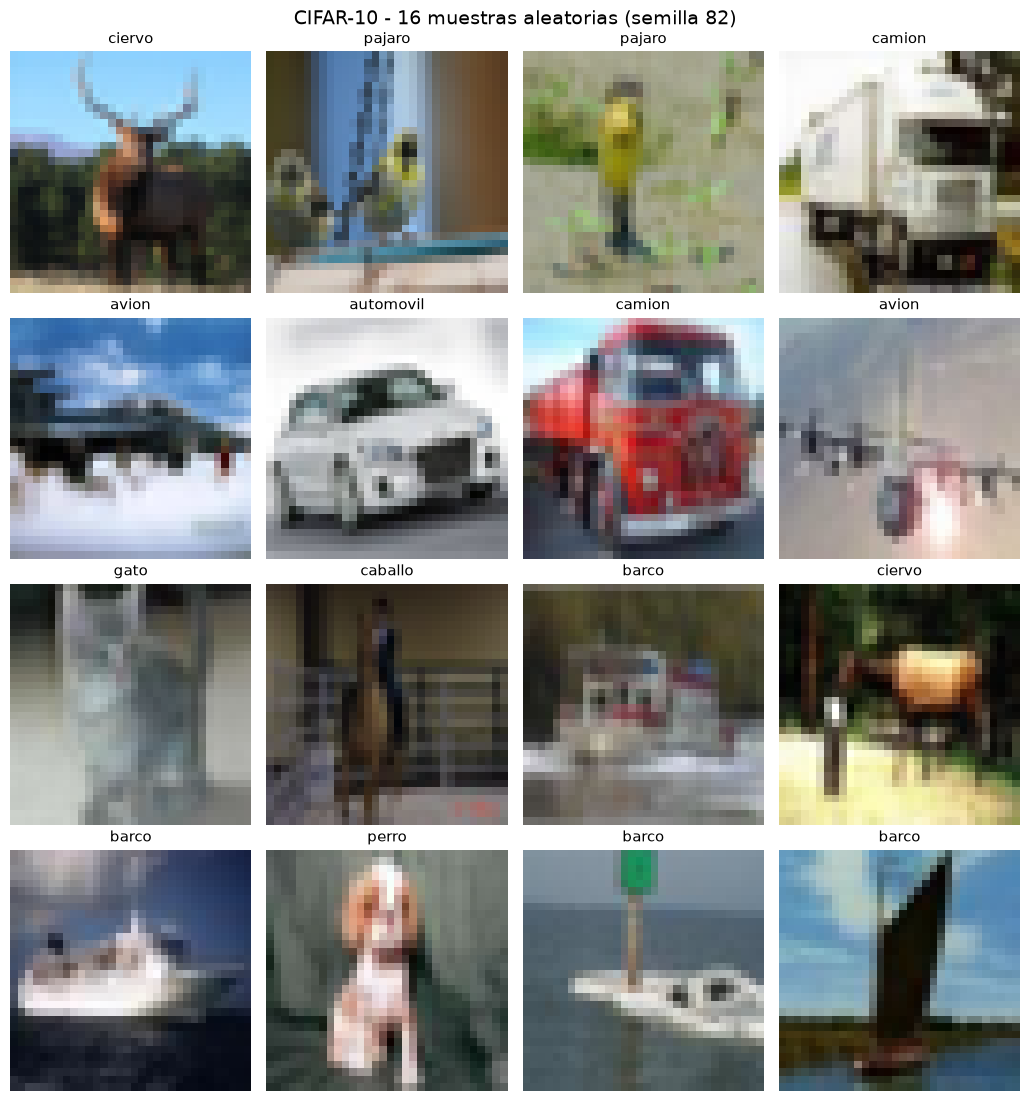

In [4]:
show_samples(16, save_path="../outputs/sample_grid.png")

### Efecto del Data Augmentation (RandomCrop + RandomHorizontalFlip)

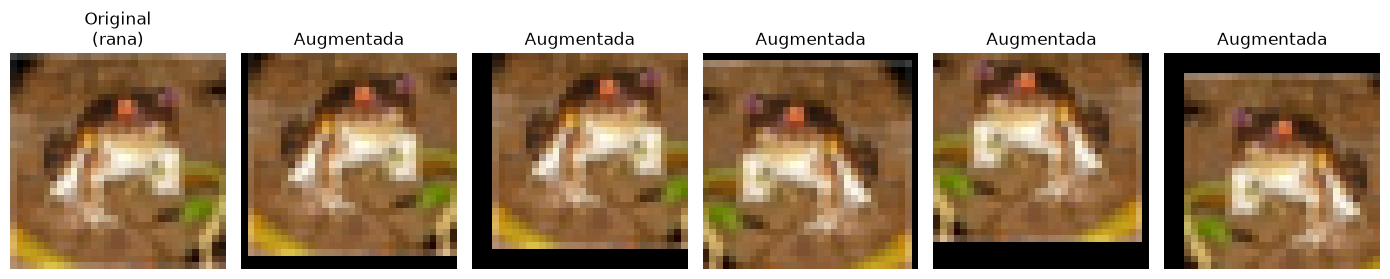

In [5]:
show_augmentation(save_path="../outputs/augmentation_examples.png")

## 5. Verificación de tensores 4D y del batch normalizado

In [6]:
xb, yb = next(iter(train_loader))
print("Batch x:", tuple(xb.shape), "-> (Batch, Channels, Height, Width)")
print("Batch y:", tuple(yb.shape))
print("Media por canal tras normalizar:", xb.mean(dim=(0, 2, 3)).numpy().round(3))
print("Std por canal tras normalizar  :", xb.std(dim=(0, 2, 3)).numpy().round(3))

Batch x: (128, 3, 32, 32) -> (Batch, Channels, Height, Width)
Batch y: (128,)
Media por canal tras normalizar: [-0.278 -0.336 -0.301]
Std por canal tras normalizar  : [1.16  1.139 1.085]


## 6. Validación del modelo (Pregunta 3)

In [7]:
model = CNN()
model.eval()
dummy = torch.randn(8, 3, 32, 32)
out = model.trace_shapes(dummy)
assert out.shape == (8, 10)
print("\nParámetros entrenables:", f"{count_parameters(model):,}")

Entrada                     (8, 3, 32, 32)
Bloque 1 (Conv-BN-ReLU-Pool)(8, 32, 16, 16)
Bloque 2 (Conv-BN-ReLU-Pool)(8, 64, 8, 8)
Bloque 3 (Conv-BN-ReLU-Pool)(8, 128, 4, 4)
Flatten                     (8, 2048)
Clasificador (Linear)       (8, 10)

Parámetros entrenables: 620,810


## 7. Prueba rápida de entrenamiento (2 épocas)
El entrenamiento completo (30 épocas) se ejecuta con `python src/train.py`.

In [8]:
import torch.nn as nn, torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(SEED)
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(2):
    model.train(); tot, ok, n = 0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x); loss = criterion(logits, y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        tot += loss.item() * len(y); ok += (logits.argmax(1) == y).sum().item(); n += len(y)
    print(f"Época {epoch+1}: loss {tot/n:.4f} | acc {100*ok/n:.2f}%")

Época 1: loss 1.6558 | acc 38.69%
Época 2: loss 1.3338 | acc 51.60%


## 8. Resultados del entrenamiento completo
Se muestran los artefactos generados por `src/train.py`.

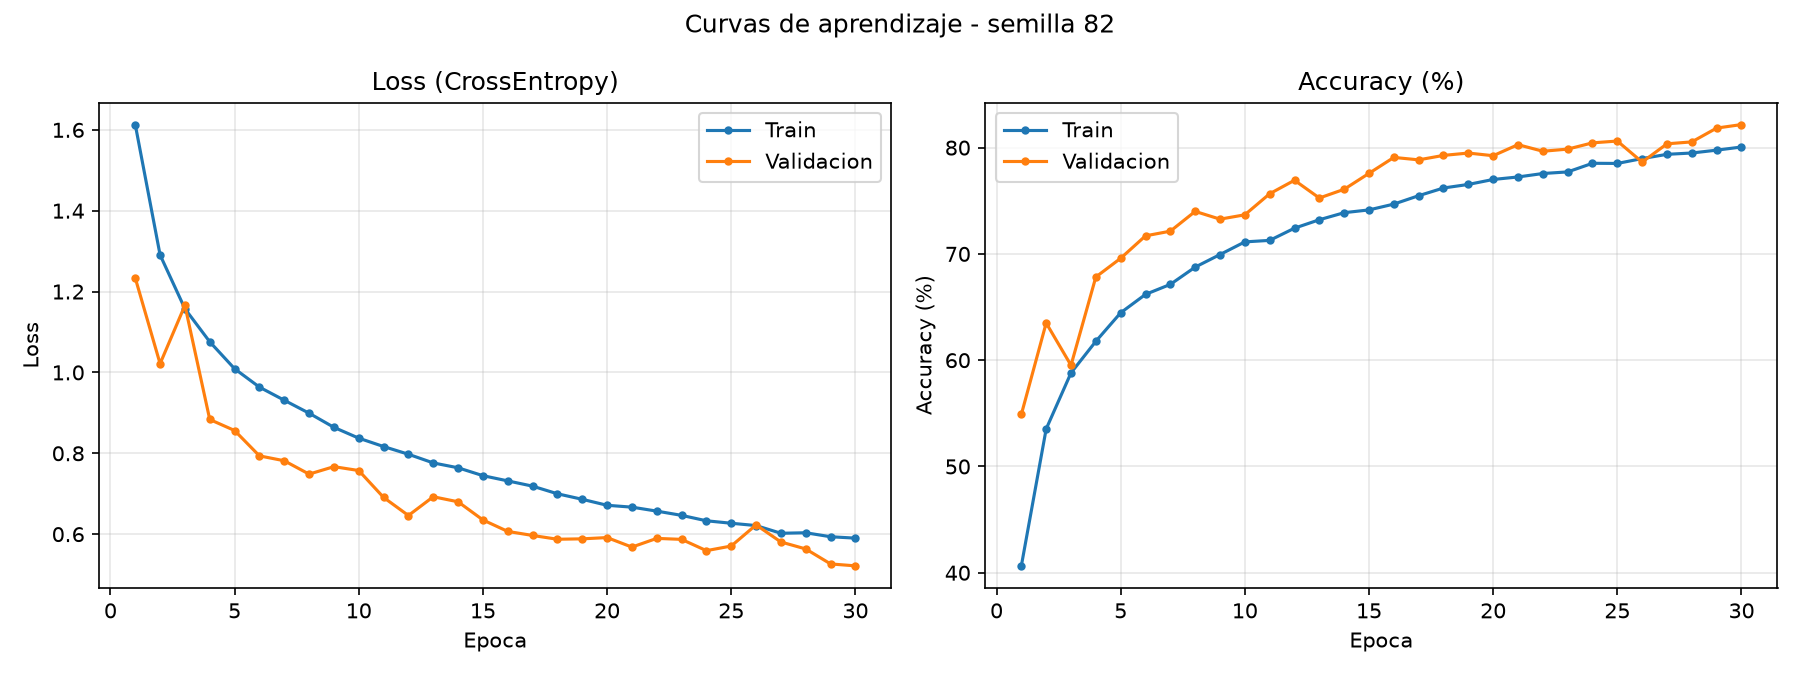

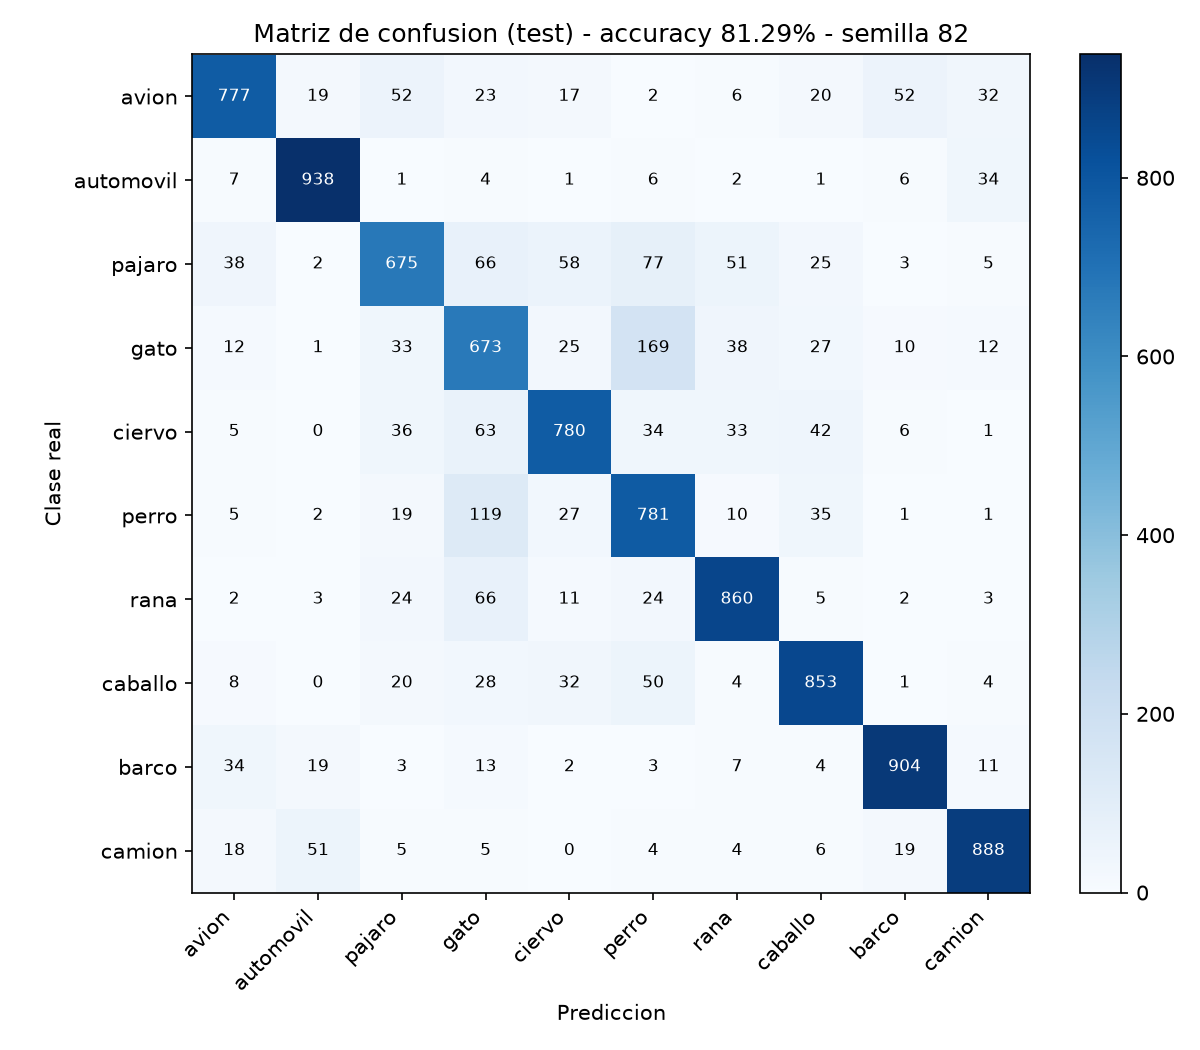

In [9]:
from IPython.display import Image, display
for f in ["loss_accuracy.png", "confusion_matrix.png"]:
    path = os.path.join("..", "outputs", f)
    if os.path.exists(path):
        display(Image(path))
    else:
        print(f"Aún no existe {f}: ejecuta primero `python src/train.py`")